<a href="https://colab.research.google.com/github/26b21a4271kiet-crypto/Artist-/blob/main/Copy_of_Loan_payment_matrix_model_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

             LOAN PAYMENT MATRIX MODEL

Enter details for Loan 1
Principal amount (₹): 10000
Annual interest rate (%): 1
Monthly EMI (₹): 500

Enter details for Loan 2
Principal amount (₹): 20000
Annual interest rate (%): 1
Monthly EMI (₹): 500

Enter details for Loan 3
Principal amount (₹): 30000
Annual interest rate (%): 3
Monthly EMI (₹): 500


TRANSITION MATRIX T
-----------------------------------------------------------------
[[   1.00083333    0.            0.         -500.        ]
 [   0.            1.00083333    0.         -500.        ]
 [   0.            0.            1.0025     -500.        ]
 [   0.            0.            0.            1.        ]]

Initial State Vector:
[[1.e+04]
 [2.e+04]
 [3.e+04]
 [1.e+00]]


CAYLEY-HAMILTON THEOREM
-----------------------------------------------------------------
Characteristic Polynomial:
1.0*lambda**4 - 4.00416666666667*lambda**3 + 6.01250486111111*lambda**2 - 4.01250972395833*lambda + 1.00417152951389

Characteristic Equation:
(

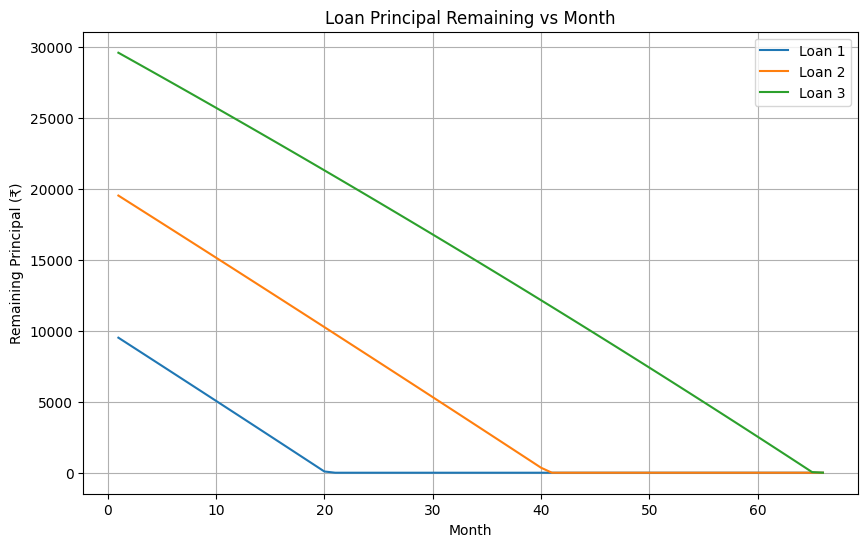


PROJECT COMPLETE


In [ ]:

import numpy as np
import sympy as sp

# ============================================================
# LOAN PAYMENT MATRIX MODEL (F7)
# Matrix Powers using Cayley-Hamilton Theorem
# ============================================================

print("=" * 65)
print("             LOAN PAYMENT MATRIX MODEL")
print("=" * 65)

# ------------------------------------------------------------
# 1. INPUT DATA
# ------------------------------------------------------------

loans = []

for i in range(3):
    print(f"\nEnter details for Loan {i + 1}")

    principal = float(input("Principal amount (₹): "))
    annual_rate = float(input("Annual interest rate (%): "))
    emi = float(input("Monthly EMI (₹): "))

    monthly_rate = annual_rate / 100 / 12

    loans.append({
        "principal": principal,
        "annual_rate": annual_rate,
        "monthly_rate": monthly_rate,
        "emi": emi
    })

# ------------------------------------------------------------
# 2. CREATE AUGMENTED TRANSITION MATRIX
#
# x(n+1) = T x(n)
#
# [P1]       [1+r1   0     0   -EMI1] [P1]
# [P2]   =   [ 0   1+r2   0   -EMI2] [P2]
# [P3]       [ 0     0   1+r3 -EMI3] [P3]
# [ 1]       [ 0     0     0      1] [ 1]
# ------------------------------------------------------------

T = np.array([
    [1 + loans[0]["monthly_rate"], 0, 0, -loans[0]["emi"]],
    [0, 1 + loans[1]["monthly_rate"], 0, -loans[1]["emi"]],
    [0, 0, 1 + loans[2]["monthly_rate"], -loans[2]["emi"]],
    [0, 0, 0, 1]
], dtype=float)

print("\n\nTRANSITION MATRIX T")
print("-" * 65)
print(T)

# ------------------------------------------------------------
# 3. INITIAL STATE VECTOR
# ------------------------------------------------------------

x0 = np.array([
    loans[0]["principal"],
    loans[1]["principal"],
    loans[2]["principal"],
    1
], dtype=float)

print("\nInitial State Vector:")
print(x0.reshape(-1, 1))

# ------------------------------------------------------------
# 4. CAYLEY-HAMILTON THEOREM
# ------------------------------------------------------------

print("\n\nCAYLEY-HAMILTON THEOREM")
print("-" * 65)

T_sym = sp.Matrix(T)

lam = sp.symbols('lambda')

char_poly = T_sym.charpoly(lam).as_expr()

print("Characteristic Polynomial:")
print(sp.expand(char_poly))

# Get coefficients
coefficients = sp.Poly(char_poly, lam).all_coeffs()

print("\nCharacteristic Equation:")
print(" + ".join(
    f"({c})*lambda^{len(coefficients)-i-1}"
    for i, c in enumerate(coefficients)
))

# Verify Cayley-Hamilton: p(T) = 0
zero_matrix = sp.zeros(4)

for i, coefficient in enumerate(coefficients):
    power = len(coefficients) - i - 1
    zero_matrix += coefficient * (T_sym ** power)

print("\nVerification of Cayley-Hamilton p(T):")
print(sp.simplify(zero_matrix))

# ------------------------------------------------------------
# 5. CALCULATE T^60
#
# We use Cayley-Hamilton reduction:
# Any power T^n can be reduced to a combination of
# I, T, T^2, T^3.
# ------------------------------------------------------------

def cayley_hamilton_power(A, n):
    """
    Calculate A^n using Cayley-Hamilton theorem.
    """

    A = sp.Matrix(A)
    size = A.rows

    x = sp.symbols('x')
    polynomial = A.charpoly(x).as_poly()

    coeffs = polynomial.all_coeffs()

    # Polynomial:
    # x^m + c1*x^(m-1) + ... + cm = 0

    m = len(coeffs) - 1

    if n < m:
        return A ** n

    # Work with polynomial remainder:
    # x^n mod characteristic polynomial
    xn = sp.Poly(x**n, x)
    remainder = xn.rem(polynomial)

    result = sp.zeros(size)

    terms = remainder.as_dict()

    for powers, coefficient in terms.items():
        power = powers[0]
        result += coefficient * (A ** power)

    return sp.simplify(result)


T60_sym = cayley_hamilton_power(T_sym, 60)

T60 = np.array(T60_sym.evalf(), dtype=float)

print("\n\nT^60 USING CAYLEY-HAMILTON THEOREM")
print("-" * 65)
print(T60)

# ------------------------------------------------------------
# 6. STATE AFTER 60 MONTHS
# ------------------------------------------------------------

x60 = T60 @ x0

# Avoid tiny numerical errors
x60 = np.where(abs(x60) < 1e-6, 0, x60)

print("\n\nSTATE AFTER 60 MONTHS")
print("-" * 65)

print(f"Loan 1 Remaining Principal: ₹{max(0, x60[0]):,.2f}")
print(f"Loan 2 Remaining Principal: ₹{max(0, x60[1]):,.2f}")
print(f"Loan 3 Remaining Principal: ₹{max(0, x60[2]):,.2f}")

# ------------------------------------------------------------
# 7. EIGENVALUE ANALYSIS
# ------------------------------------------------------------

print("\n\nEIGENVALUE ANALYSIS")
print("-" * 65)

eigenvalues = np.linalg.eigvals(T)

for i, value in enumerate(eigenvalues, 1):
    print(f"Eigenvalue {i}: {value:.6f}")

print("\nInterpretation:")
print("Eigenvalues describe the long-term behavior of the")
print("transition matrix and are useful for stability analysis.")

# ------------------------------------------------------------
# 8. MONTH-BY-MONTH LOAN SIMULATION
#
# This section determines:
# - Monthly balance
# - Monthly interest
# - Total interest
# - Payoff month
# ------------------------------------------------------------

balances = np.array([
    loans[0]["principal"],
    loans[1]["principal"],
    loans[2]["principal"]
], dtype=float)

total_interest = np.zeros(3)

payoff_month = [None, None, None]

history = []

for month in range(1, 361):  # Maximum 30 years

    monthly_balances = []

    for i in range(3):

        if balances[i] <= 0:
            balances[i] = 0
            monthly_balances.append(0)
            continue

        # Interest for current month
        interest = balances[i] * loans[i]["monthly_rate"]

        # Add to total interest
        total_interest[i] += interest

        # Principal reduction
        principal_payment = loans[i]["emi"] - interest

        # New balance
        new_balance = balances[i] - principal_payment

        if new_balance <= 0:

            # Loan paid off
            new_balance = 0

            if payoff_month[i] is None:
                payoff_month[i] = month

        balances[i] = new_balance

        monthly_balances.append(new_balance)

    history.append(monthly_balances)

    # Stop when all loans are paid
    if all(balance == 0 for balance in balances):
        break

# ------------------------------------------------------------
# 9. FINAL RESULTS
# ------------------------------------------------------------

print("\n\nFINAL LOAN ANALYSIS")
print("=" * 65)

for i in range(3):

    print(f"\nLoan {i + 1}")
    print("-" * 30)

    if payoff_month[i] is not None:
        print(f"Paid Off Month       : {payoff_month[i]}")
        print(f"Paid Off After       : "
              f"{payoff_month[i] // 12} years "
              f"{payoff_month[i] % 12} months")
    else:
        print("Paid Off             : Not within 30 years")

    print(f"Total Interest Paid  : ₹{total_interest[i]:,.2f}")

print("\n" + "=" * 65)

print(f"TOTAL INTEREST PAID: ₹{sum(total_interest):,.2f}")

print("=" * 65)

# ------------------------------------------------------------
# 10. 5-YEAR SUMMARY
# ------------------------------------------------------------

print("\n\n5-YEAR (60 MONTH) SUMMARY")
print("=" * 65)

for i in range(3):

    balance_60 = max(0, x60[i])

    print(
        f"Loan {i + 1}: "
        f"₹{balance_60:,.2f} remaining"
    )

print("=" * 65)

# ------------------------------------------------------------
# 11. VERIFY T^60 USING DIRECT MATRIX POWER
# ------------------------------------------------------------

direct_T60 = np.linalg.matrix_power(T, 60)

difference = np.max(np.abs(T60 - direct_T60))

print("\n\nCAYLEY-HAMILTON VERIFICATION")
print("-" * 65)

print(f"Maximum difference between")
print(f"C-H result and direct T^60:")
print(f"{difference:.10f}")

if difference < 1e-5:
    print("\n✓ CAYLEY-HAMILTON RESULT VERIFIED")
else:
    print("\n✗ CHECK NUMERICAL PRECISION")

# ------------------------------------------------------------
# 12. OPTIONAL GRAPH
# ------------------------------------------------------------

try:
    import matplotlib.pyplot as plt

    history_array = np.array(history)

    months = np.arange(1, len(history_array) + 1)

    plt.figure(figsize=(10, 6))

    plt.plot(
        months,
        history_array[:, 0],
        label="Loan 1"
    )

    plt.plot(
        months,
        history_array[:, 1],
        label="Loan 2"
    )

    plt.plot(
        months,
        history_array[:, 2],
        label="Loan 3"
    )

    plt.xlabel("Month")
    plt.ylabel("Remaining Principal (₹)")
    plt.title("Loan Principal Remaining vs Month")
    plt.legend()
    plt.grid(True)

    plt.show()

except ImportError:
    print("\nMatplotlib is not installed.")
    print("Install it using: pip install matplotlib")

print("\nPROJECT COMPLETE")